# 02 Primer entrenamiento de alerta semanal de dengue

Este ejercicio entrena una **regresión logística con penalización L2** para estimar la probabilidad de exceso en la semana siguiente al corte nominal, según la definición P75 del notebook 01. Se compara con referencias simples. HistGradientBoostingClassifier queda para la siguiente comparación; todavía no hay búsqueda entre familias de modelos.

**Pregunta:** ¿Podemos predecir, a partir de los casos de dengue de las semanas anteriores y la época del año, si los casos de la próxima semana en Ibagué superarán el umbral histórico correspondiente a esa semana?

Los diez predictores proceden de semanas recientes y del calendario. El P75 de la misma semana de años anteriores define la etiqueta `exceso`, pero esos conteos anuales no entran directamente como predictores. El modelo devuelve una probabilidad; una regla posterior la transforma en alerta. No se pronostica el número exacto de casos.

**Ejecución:** por defecto se valida y reutiliza el modelo local si coincide con los datos, configuración y variables actuales. Si falta o cambió alguno de esos elementos, se entrena de nuevo. Para repetir explícitamente el ajuste, establecer `REENTRENAR=True` en la sección 3. Repetir el mismo ajuste no convierte a 2024 en una prueba nueva.

La evaluación es retrospectiva sobre notificaciones finales: no demuestra rendimiento en tiempo real ni capacidad para detectar brotes definidos por una fuente externa. Ejecutar primero el notebook 01.

## 1 Entorno y carga del panel validado

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/piloto.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from dengue.pipeline import *
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (12,4), 'font.size': 10})
SALIDA = raiz_salida(config('ibague'))
FIG = SALIDA/'reports/figures'
FIG.mkdir(parents=True, exist_ok=True)
cfg = config('ibague')
display(pd.Series(cfg, name='Configuración acordada').to_frame())

,Configuración acordada
municipio,73001
nombre_municipio,Ibagué
anio_inicial,2007
anio_final,2025
ventana_canal_anios,5
cuantil_canal,0.75
min_anios_canal,5
fin_entrenamiento,2021
fin_validacion,2023
anio_prueba,2024


In [2]:
panel = pd.read_csv(SALIDA/'data/processed/ibague_panel_semanal.csv',
    dtype={'cod_municipio':'string'}, parse_dates=['inicio_semana','fin_semana','corte_prediccion'])
assert cfg['fecha_principal']=='INI_SIN' and cfg['politica_fecha_faltante']=='excluir_sin_sustituir'
assert cfg['horizonte_semanas']==1, 'Este experimento implementa un horizonte de una semana.'
assert not panel.duplicated(['anio_epi','semana_epi']).any()
assert panel.inicio_semana.diff().dropna().eq(pd.Timedelta(days=7)).all()
assert panel.corte_prediccion.eq(panel.inicio_semana-pd.Timedelta(days=1)).all()
reconstruido = agregar_features(agregar_canal(panel,cfg))
np.testing.assert_allclose(panel[FEATURES+['umbral_casos','exceso']],
    reconstruido[FEATURES+['umbral_casos','exceso']],equal_nan=True,atol=1e-12)
assert panel.elegible_modelo.eq(reconstruido.elegible_modelo).all()
assert set(FEATURES).isdisjoint({'casos','umbral_casos','exceso','casos_confirmados','hospitalizados'})
datos = panel.loc[panel.elegible_modelo].copy()
print('Observaciones elegibles:',len(datos))
display(datos.groupby('anio_epi').exceso.agg(['count','sum','mean']).rename(columns={'sum':'positivos','mean':'prevalencia'}))

Observaciones elegibles: 708


,count,positivos,prevalencia
anio_epi,,,
2012,52,38.0,0.730769
2013,52,44.0,0.846154
2014,52,9.0,0.173077
2015,52,28.0,0.538462
2016,52,4.0,0.076923
2017,52,0.0,0.000000
2018,52,0.0,0.000000
2019,52,35.0,0.673077
2020,52,15.0,0.288462


## 2 Partición cronológica y propósito de cada bloque

- Hasta 2021: ajuste del escalador y de los coeficientes.
- 2022–2023: elección del umbral de probabilidad, maximizando F2 en una rejilla predefinida; en empates se prefiere el umbral mayor.
- 2024: evaluación de referencia, sin usarla para ajustar coeficientes o escoger umbral en esta ejecución. Se reserva para evaluar después del ajuste y de seleccionar el umbral en validación.
- 2025: evaluación adicional; las cifras requieren revisar cobertura y cambio de comportamiento.

El canal de cada fila se calcula con sus años anteriores. La validación y prueba pueden usar semanas ya observadas anteriores dentro de su propio bloque, sin reentrenar: se simulan orígenes móviles de un paso con datos finales. No equivale a predecir todo el bloque desde un único corte. No hay escalado ni selección de variables con prueba.

In [3]:
particiones_previas = datos.assign(bloque=np.select(
    [datos.anio_epi<=cfg['fin_entrenamiento'],
     datos.anio_epi.between(cfg['fin_entrenamiento']+1,cfg['fin_validacion']),
     datos.anio_epi.eq(cfg['anio_prueba']),datos.anio_epi.eq(cfg['anio_adicional'])],
    ['entrenamiento','validacion',f"prueba_{cfg['anio_prueba']}",f"adicional_{cfg['anio_adicional']}"],
    default='fuera_del_diseno'))
assert particiones_previas.bloque.ne('fuera_del_diseno').all(), 'Hay años sin bloque de evaluación definido.'
display(particiones_previas.groupby('bloque').agg(n=('exceso','size'),
    positivos=('exceso','sum'),inicio=('inicio_semana','min'),fin=('fin_semana','max')))
print('Variables:',FEATURES)

,n,positivos,inicio,fin
bloque,,,,
adicional_2025,50,1.0,2024-12-29,2025-12-27
entrenamiento,515,173.0,2012-01-01,2022-01-01
prueba_2024,50,41.0,2023-12-31,2024-12-28
validacion,93,38.0,2022-01-02,2023-12-30


Variables: ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_8', 'lag_12', 'media_4', 'std_4', 'semana_sin', 'semana_cos']


## 3 Entrenar el modelo y las referencias

El pipeline ajusta `StandardScaler` con entrenamiento y después `LogisticRegression(C=1, penalty L2 por defecto, solver=lbfgs)`. Los hiperparámetros se fijan antes de mirar prueba. No se aplica SMOTE ni se mezclan fechas.

Referencias: probabilidad constante igual a prevalencia de entrenamiento; persistencia de conteo, que pronostica el último conteo observado y lo contrasta con el umbral conocido del objetivo; y la regla trivial de alertar siempre. Las decisiones binarias de referencia no son probabilidades calibradas. Se informa también la logística a umbral 0,5 para separar el efecto del modelo del efecto del umbral.

In [4]:
import joblib
from dengue.validacion_modelo import coincide_artefacto, verificar_resultados
REENTRENAR = False
version = cfg['version_experimento']
ruta_artefacto = SALIDA/f'modelos/logistica_ibague_{version}.joblib'
tablas = SALIDA/'reports/tables'
archivos = ['metricas_logistica.csv','predicciones_logistica.csv','particiones_temporales.csv',
            'coeficientes_logistica.csv','seleccion_umbral_validacion.csv']
artefacto = joblib.load(ruta_artefacto) if ruta_artefacto.exists() else None
reutilizar = (not REENTRENAR and artefacto is not None
    and coincide_artefacto(panel,cfg,artefacto['metadata'])
    and all((tablas/f).exists() for f in archivos))
if reutilizar:
    model, metadata = artefacto['pipeline'], artefacto['metadata']
    metricas = pd.read_csv(tablas/'metricas_logistica.csv')
    predicciones = pd.read_csv(tablas/'predicciones_logistica.csv',parse_dates=['inicio_semana'])
    particiones = pd.read_csv(tablas/'particiones_temporales.csv')
    coeficientes = pd.read_csv(tablas/'coeficientes_logistica.csv')
    print('Modelo reutilizado: coinciden panel, configuración, variables y versión. No se reentrenó.')
else:
    model, metricas, predicciones, particiones, coeficientes = entrenar_logistica(panel,cfg)
    metadata = joblib.load(ruta_artefacto)['metadata']
    print('Modelo entrenado: ajuste solicitado o artefacto/resultados ausentes o incompatibles.')
controles = verificar_resultados(panel,cfg,model,metadata,metricas,predicciones,particiones,coeficientes)
display(controles)
display(particiones)
tabla_umbrales = pd.read_csv(tablas/'seleccion_umbral_validacion.csv')
from sklearn.metrics import fbeta_score
val = datos.loc[datos.anio_epi.between(cfg['fin_entrenamiento']+1,cfg['fin_validacion'])]
prob_val = model.predict_proba(val[FEATURES])[:,1]
np.testing.assert_allclose(tabla_umbrales.f2_validacion,
    [fbeta_score(val.exceso,prob_val>=t,beta=2,zero_division=0) for t in tabla_umbrales.umbral])
display(tabla_umbrales.sort_values(['f2_validacion','umbral'],ascending=False).head(6))
print('Umbral de probabilidad validado:',round(metadata['umbral_probabilidad'],2))
positivos_validacion = int(val.exceso.sum())
print('Semanas con exceso en validación:', positivos_validacion)
if positivos_validacion < 10:
    print('LIMITACIÓN: pocos excesos en validación; el umbral y la sensibilidad son inestables.')
if tabla_umbrales.f2_validacion.max() == 0:
    print('LIMITACIÓN: F2 es cero en toda la rejilla. El umbral resulta del desempate; no acredita capacidad de alerta.')
print('Las limitaciones se conservan como resultado del primer experimento, sin ajustar con prueba.')


Modelo entrenado: ajuste solicitado o artefacto/resultados ausentes o incompatibles.


,bloque,semanas_verificadas,metodos_verificados,predicciones_y_metricas
0,entrenamiento,515,5,coinciden
1,validacion,93,5,coinciden
2,prueba_2024,50,5,coinciden
3,adicional_2025,50,5,coinciden


,bloque,filas,positivos,inicio,fin
0,entrenamiento,515,173,2012-01-01,2022-01-01
1,validacion,93,38,2022-01-02,2023-12-30
2,prueba_2024,50,41,2023-12-31,2024-12-28
3,adicional_2025,50,1,2024-12-29,2025-12-27


,umbral,f2_validacion
0,0.10,0.820106
1,0.15,0.810811
2,0.20,0.773481
3,0.25,0.730337
4,0.30,0.681818
5,0.35,0.632184


Umbral de probabilidad validado: 0.1
Semanas con exceso en validación: 38
Las limitaciones se conservan como resultado del primer experimento, sin ajustar con prueba.


### 3.1 Probabilidad, alerta y comprobación del resultado

El modelo estima una probabilidad de exceso. La alerta se activa si esa probabilidad alcanza el umbral elegido con validación. `umbral_casos` está en número de notificaciones y define el evento que queremos anticipar; `umbral_probabilidad` es un parámetro de decisión aplicado a la salida del clasificador.

La tabla siguiente ilustra semanas de validación: el corte y las variables preceden al objetivo; los casos y la etiqueta observada solo se muestran para comprobar después el resultado. Es un ejemplo retrospectivo, no una alerta actual emitida en tiempo real.

In [5]:
ejemplo = predicciones.loc[predicciones.bloque.eq('validacion')
    & predicciones.modelo.eq('logistica_umbral_validado')].head(5).copy()
ejemplo['inicio_semana'] = pd.to_datetime(ejemplo.inicio_semana)
ejemplo = ejemplo.merge(panel[['inicio_semana','corte_prediccion']],on='inicio_semana',validate='one_to_one')
ejemplo['umbral_probabilidad'] = metadata['umbral_probabilidad']
display(ejemplo[['corte_prediccion','inicio_semana','probabilidad','umbral_probabilidad',
                'prediccion','casos','umbral_casos','exceso']].rename(columns={
    'inicio_semana':'semana_objetivo','prediccion':'alerta','casos':'casos_observados_despues',
    'exceso':'etiqueta_observada_despues'}).round(4))

C:\Users\aicra\OneDrive\UNIANDES\Despliegue\Codigo\Repos\ModeloDengue\ModeloDengue\.cache\tmp\ipykernel_85848\2784298186.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  'exceso':'etiqueta_observada_despues'}).round(4))


,corte_prediccion,semana_objetivo,probabilidad,umbral_probabilidad,alerta,casos_observados_despues,umbral_casos,etiqueta_observada_despues
0,2022-01-01,2022-01-02,0.0127,0.1,0,6.0,27.0,0.0
1,2022-01-08,2022-01-09,0.0115,0.1,0,5.0,18.0,0.0
2,2022-02-26,2022-02-27,0.0071,0.1,0,2.0,22.0,0.0
3,2022-03-05,2022-03-06,0.0074,0.1,0,9.0,24.0,0.0
4,2022-03-12,2022-03-13,0.0095,0.1,0,4.0,21.0,0.0


## 4 Métricas fuera de entrenamiento

Sensibilidad: qué proporción de semanas con exceso detectamos. Precisión: qué proporción de alertas corresponde a exceso. AP resume la curva precisión–recobrado (no es el área trapezoidal). Brier evalúa error de probabilidad; menor es mejor. La matriz de confusión permite contar falsas alarmas y excesos omitidos.

La evaluación se hace contra nuestra etiqueta histórica, no contra una lista independiente de brotes. Los resultados de entrenamiento son descriptivos y no evidencia de generalización. Las AUC se dejan vacías si el bloque contiene una sola clase; sensibilidad y F1/F2 se dejan vacíos cuando no hay positivos reales. La precisión queda vacía cuando no se emitió ninguna alerta.

**Lectura crítica:** revisar prevalencia y matriz de confusión junto a sensibilidad y F1. Si un bloque tiene casi todas las semanas positivas, alertar siempre puede obtener métricas altas. La persistencia es una referencia exigente. La reconstrucción v1 responde a una decisión de calidad de datos, no a elegir el resultado que mejore prueba. En Cali 2024 ya fue observado; en este municipio esta es la primera evaluación. No se usa prueba para seleccionar el umbral.

In [6]:
cols=['bloque','modelo','n','prevalencia','umbral_probabilidad','sensibilidad','especificidad','precision','f1','f2','pr_auc_AP','roc_auc','brier','tn','fp','fn','tp']
display(metricas.loc[metricas.bloque.ne('entrenamiento'),cols].round(4))
print('Resumen de validación: compara capacidad predictiva con una referencia sencilla.')
resumen = metricas.loc[metricas.bloque.eq('validacion') & metricas.modelo.isin(
    ['logistica_umbral_validado','persistencia_conteo']),
    ['modelo','sensibilidad','precision','f1','fp','fn']].copy()
for c in ['sensibilidad','precision','f1']:
    resumen[c] = 100*resumen[c]
display(resumen.rename(columns={'sensibilidad':'sensibilidad (%)','precision':'precisión (%)','f1':'F1 (%)',
    'fp':'falsas alarmas','fn':'excesos omitidos'}).round(1))

,bloque,modelo,n,prevalencia,umbral_probabilidad,sensibilidad,especificidad,precision,f1,f2,pr_auc_AP,roc_auc,brier,tn,fp,fn,tp
5,validacion,logistica_umbral_validado,93,0.4086,0.1,0.8158,0.8909,0.8378,0.8267,0.8201,0.8982,0.8694,0.1466,49,6,7,31
6,validacion,logistica_umbral_0_5,93,0.4086,0.5,0.5263,1.0000,1.0000,0.6897,0.5814,0.8982,0.8694,0.1466,55,0,18,20
7,validacion,prevalencia_entrenamiento,93,0.4086,0.5,0.0000,1.0000,NaN,0.0000,0.0000,0.4086,0.5000,0.2469,55,0,38,0
8,validacion,siempre_alerta,93,0.4086,0.5,1.0000,0.0000,0.4086,0.5802,0.7755,0.4086,0.5000,0.5914,0,55,0,38
9,validacion,persistencia_conteo,93,0.4086,0.5,0.8684,0.9455,0.9167,0.8919,0.8777,0.8498,0.9069,0.0860,52,3,5,33
10,prueba_2024,logistica_umbral_validado,50,0.8200,0.1,1.0000,0.0000,0.8200,0.9011,0.9579,0.9897,0.9485,0.1338,0,9,0,41
11,prueba_2024,logistica_umbral_0_5,50,0.8200,0.5,0.9756,0.0000,0.8163,0.8889,0.9390,0.9897,0.9485,0.1338,0,9,1,40
12,prueba_2024,prevalencia_entrenamiento,50,0.8200,0.5,0.0000,1.0000,NaN,0.0000,0.0000,0.8200,0.5000,0.3819,9,0,41,0
13,prueba_2024,siempre_alerta,50,0.8200,0.5,1.0000,0.0000,0.8200,0.9011,0.9579,0.8200,0.5000,0.1800,0,9,0,41
14,prueba_2024,persistencia_conteo,50,0.8200,0.5,0.9512,0.7778,0.9512,0.9512,0.9512,0.9448,0.8645,0.0800,7,2,2,39


Resumen de validación: compara capacidad predictiva con una referencia sencilla.


,modelo,sensibilidad (%),precisión (%),F1 (%),falsas alarmas,excesos omitidos
5,logistica_umbral_validado,81.6,83.8,82.7,6,7
9,persistencia_conteo,86.8,91.7,89.2,3,5


## 5 Matriz de confusión de prueba y evolución de probabilidades

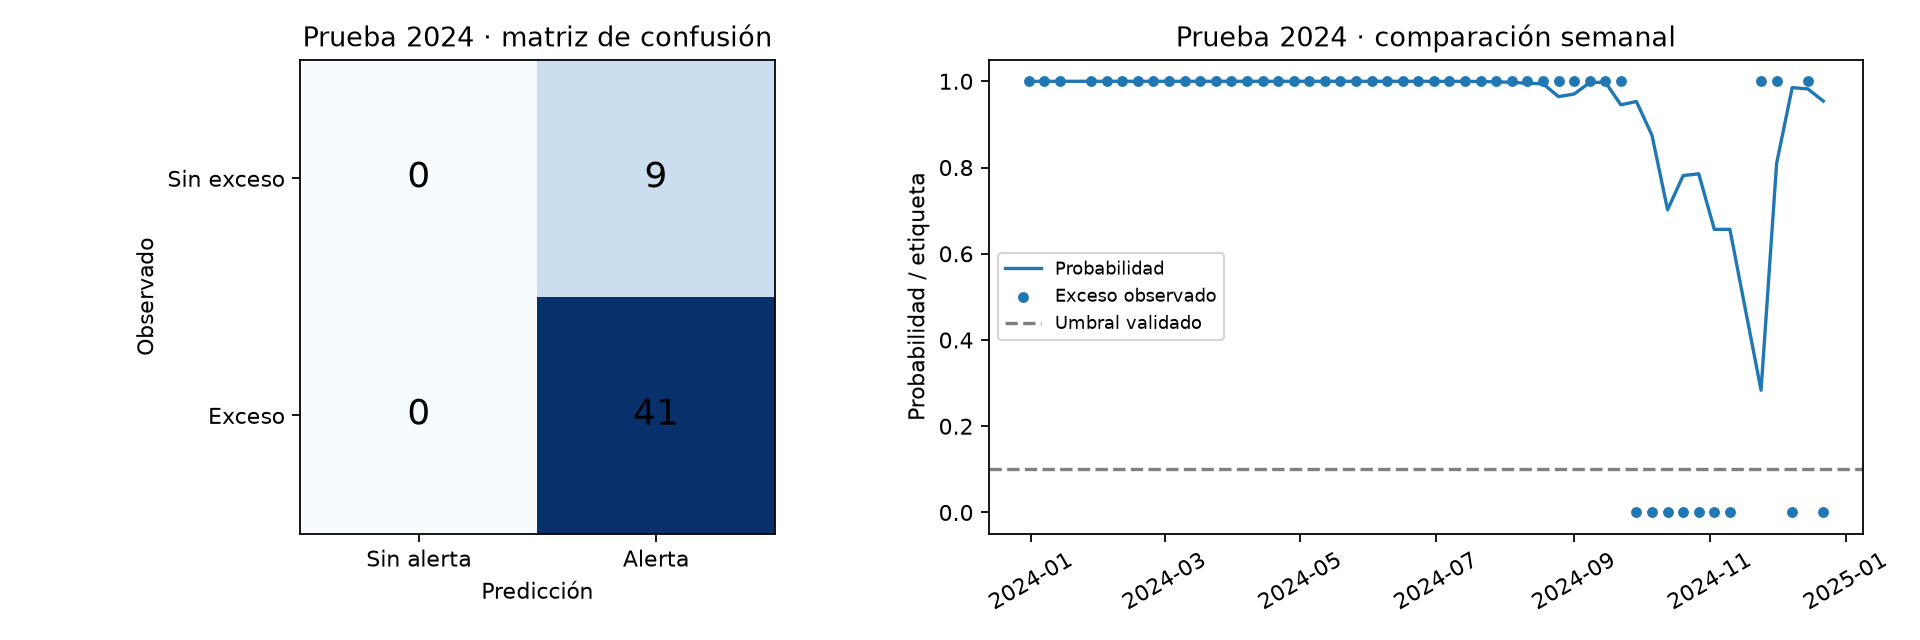

In [7]:
row=metricas.loc[(metricas.bloque=='prueba_2024')&(metricas.modelo=='logistica_umbral_validado')].iloc[0]
matrix=np.array([[row.tn,row.fp],[row.fn,row.tp]],dtype=int)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].imshow(matrix,cmap='Blues')
for (i,j),value in np.ndenumerate(matrix):axes[0].text(j,i,str(value),ha='center',va='center',fontsize=16)
axes[0].set(xticks=[0,1],yticks=[0,1],xticklabels=['Sin alerta','Alerta'],yticklabels=['Sin exceso','Exceso'],
            xlabel='Predicción',ylabel='Observado',title='Prueba 2024 · matriz de confusión')
q=predicciones.loc[(predicciones.bloque=='prueba_2024')&(predicciones.modelo=='logistica_umbral_validado')]
axes[1].plot(q.inicio_semana,q.probabilidad,label='Probabilidad')
axes[1].scatter(q.inicio_semana,q.exceso,label='Exceso observado',s=15)
axes[1].axhline(row.umbral_probabilidad,linestyle='--',color='gray',label='Umbral validado')
axes[1].set(ylabel='Probabilidad / etiqueta',title='Prueba 2024 · comparación semanal',ylim=(-.05,1.05))
axes[1].tick_params(axis='x',rotation=30);axes[1].legend(fontsize=8)
fig.tight_layout();fig.savefig(FIG/'04_prueba_logistica.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'04_prueba_logistica.png')))

## 6 Inspección de probabilidades y coeficientes

La curva de calibración es descriptiva: con pocas semanas no permite afirmar calibración robusta. Los coeficientes estandarizados representan asociaciones condicionadas al resto de variables y pueden ser inestables por correlación entre rezagos; no tienen interpretación causal.

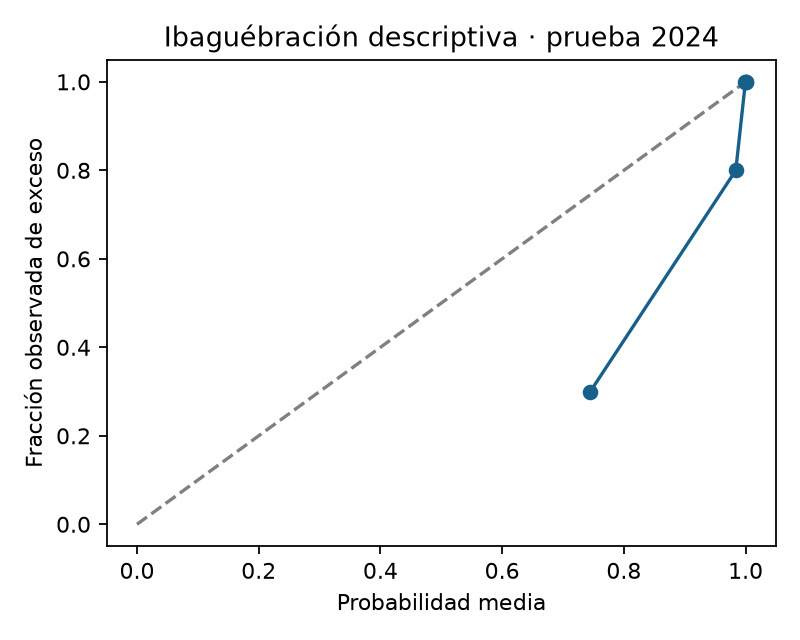

,variable,coeficiente_estandarizado
0,lag_1,1.7054
8,semana_sin,-0.6773
6,media_4,0.6405
9,semana_cos,-0.6102
5,lag_12,-0.5957
1,lag_2,0.5327
3,lag_4,0.2451
2,lag_3,0.0282
4,lag_8,-0.0207
7,std_4,-0.0200


In [8]:
from sklearn.calibration import calibration_curve
frac, mean = calibration_curve(q.exceso,q.probabilidad,n_bins=5,strategy='quantile')
fig,ax=plt.subplots(figsize=(5,4));ax.plot([0,1],[0,1],'--',color='gray');ax.plot(mean,frac,'o-',color='#17608a')
ax.set(xlabel='Probabilidad media',ylabel='Fracción observada de exceso',title='Ibaguébración descriptiva · prueba 2024')
fig.tight_layout();fig.savefig(FIG/'05_calibracion_prueba.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'05_calibracion_prueba.png')))
display(coeficientes.sort_values('coeficiente_estandarizado',key=abs,ascending=False).round(4))

## 7 Artefactos y lectura de resultados

Se verificaron métricas por bloque, predicciones, selección del umbral, coeficientes y el artefacto local con metadatos. Si no hubo cambios en los datos o la configuración, se reutilizó el modelo; la salida de la sección 3 informa la acción ejecutada. Se comprobó la huella del panel, el ajuste del escalador solo con entrenamiento y la coincidencia entre inferencias actuales, matrices de confusión y métricas guardadas. El modelo sigue ajustado solo hasta 2021; no se presenta como versión operacional final.

Una buena métrica no resuelve las limitaciones de disponibilidad: los rezagos contienen conteos finales que pudieron notificarse más tarde. Antes de desplegar debemos revisar este supuesto con el experto y evaluar latencias o construir una versión basada en datos disponibles por notificación. Tampoco se ha validado la cobertura de semanas sin registros.

La comparación siguiente debe mantener este protocolo y reservar una evaluación nueva si se usa repetidamente 2024 para tomar decisiones. Prioridades: sensibilidad del canal, validación temporal de HistGradientBoostingClassifier, oportunidad por episodios y comparación municipal. No se afirma que la logística sea el mejor modelo por haber sido el primero.

Referencias: [validación temporal scikit-learn](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split) y [Umaña et al.](https://publichealth.jmir.org/2026/1/e79914).